# Đánh giá YOLO26s (LR = 0,000667) và YOLO26n
**Dùng chung một tập Test cho cả hai mô hình.** Chạy các cell đầu chuẩn bị dữ liệu đúng một lần, sau đó đánh giá YOLO26s và chạy N1–N7 cho YOLO26n. Không huấn luyện lại mô hình.

- **Checkpoint YOLO26s:** `yolo26s_rdd_3class_best.pt` trong Kaggle Model .
- **Checkpoint YOLO26n:** `yolo26n_rdd_3class_best.pt` trong Kaggle Model Nano.
- **Thống kê theo ảnh / ma trận:** `conf=0.25`, `NMS IoU=0.45`, `nms=True`, `agnostic_nms=False`.
- **Ghép vị trí theo ảnh:** IoU ≥ 0.50. **mAP chính thức:** đánh giá bằng `model.val()` với ngưỡng mặc định, tách riêng với thống kê theo ảnh.

**Yêu cầu:** Gắn vào Kaggle Input một dataset DataKhuyen và **cả hai** model trên. Cell cấu hình sẽ liệt kê đường dẫn rồi xác thực, dừng nếu tìm nhầm model.


### Cell 1 — Cài đặt và cấu hình
Cài thư viện trong phiên Kaggle mới và kiểm tra checkpoint, GPU, đường dẫn dữ liệu.
Không huấn luyện lại mô hình; chỉ dùng trọng số `best.pt` để suy luận.

In [ ]:

# ============================================================
# CELL 1 - CAI DAT VA CAU HINH
# YOLO26n + YOLO26s | RDD2022 TEST
# ============================================================

%pip install -q ultralytics==8.4.213 pandas pyyaml pillow matplotlib seaborn

import os
import sys
import json
import time
import zipfile
import shutil
import re

from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import yaml
import torch
import matplotlib.pyplot as plt
from PIL import Image

import ultralytics
from ultralytics import YOLO
from IPython.display import display, FileLink


# ============================================================
# 1. THU MUC DU LIEU VA KET QUA
# ============================================================

INPUT = Path("/kaggle/input")

ROOT = Path("/kaggle/working/road_damage_analysis")
ROOT.mkdir(parents=True, exist_ok=True)

DATASET_OUT = Path("/kaggle/working/dataset_3class")

# Ket qua YOLO26s
RESULTS = ROOT / "results_yolo26s"
RESULTS.mkdir(parents=True, exist_ok=True)

# Ket qua YOLO26n
RESULTS_N = ROOT / "results_yolo26n"
RESULTS_N.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. DUONG DAN CHECKPOINT CHINH XAC
# ============================================================

# YOLO26s - Learning Rate = 0.000667
MODEL_PATH = Path(
    "/kaggle/input/models/vtmhhh/"
    "yolo26s-lr-0-00067-hihi/"
    "pytorch/default/1/"
    "yolo26s_rdd_3class_best.pt"
)

# YOLO26n - Learning Rate = 0.000667
MODEL_PATH_N = Path(
    "/kaggle/input/models/vtmhhh/"
    "yolo26n-lr-0-00067/"
    "pytorch/default/1/"
    "yolo26n_rdd_3class_best.pt"
)


# ============================================================
# 3. KIEM TRA CHECKPOINT
# ============================================================

assert MODEL_PATH.is_file(), (
    f"Khong tim thay YOLO26s: {MODEL_PATH}"
)

assert MODEL_PATH_N.is_file(), (
    f"Khong tim thay YOLO26n: {MODEL_PATH_N}"
)

assert MODEL_PATH.resolve() != MODEL_PATH_N.resolve(), (
    "Hai checkpoint dang trung nhau!"
)

print("CHECKPOINT DA TIM THAY:")
print("YOLO26s:", MODEL_PATH)
print("YOLO26n:", MODEL_PATH_N)


# ============================================================
# 4. CAU HINH BO DU LIEU
# ============================================================

CLASSES = {
    0: "pothole",
    1: "linear_crack",
    2: "alligator_crack"
}

EXPECTED_IMAGES = 2196
EXPECTED_BOXES = 4548

IMAGE_EXTS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}


# ============================================================
# 5. CAU HINH SUY LUAN VA DANH GIA
# ============================================================

IMGSZ = 640

# Nguong loc theo do tin cay
CONF = 0.25

# Nguong IoU cua NMS
NMS_IOU = 0.45

# Nguong IoU ghep du doan voi Ground Truth
MATCH_IOU = 0.50

# CPU / GPU
DEVICE = 0 if torch.cuda.is_available() else "cpu"

BATCH = 16 if torch.cuda.is_available() else 4


# ============================================================
# 6. KIEM TRA PHIEN BAN ULTRALYTICS
# ============================================================

print("\nPHIEN BAN THU VIEN:")
print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)

assert ultralytics.__version__ == "8.4.213", (
    "Sai phien ban Ultralytics. "
    "Hay restart kernel va chay lai Cell 1."
)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Dang su dung CPU")


# ============================================================
# 7. NAP YOLO26s
# ============================================================

# Giu ten bien 'model' de tuong thich
# voi cac Cell 3-8 cua notebook goc

model = YOLO(str(MODEL_PATH))

model_classes = {
    int(k): str(v)
    for k, v in model.names.items()
}

assert model_classes == CLASSES, (
    f"Thu tu lop YOLO26s khong dung: {model.names}"
)

print("\nDA NAP YOLO26s THANH CONG")
print("Classes:", model.names)


# ============================================================
# 8. KIEM TRA CAU HINH CUOI CUNG
# ============================================================

print("\n========== CAU HINH TEST ==========")

print("YOLO26s:", MODEL_PATH.name)
print("YOLO26n:", MODEL_PATH_N.name)

print("Image size:", IMGSZ)
print("Confidence:", CONF)
print("NMS IoU:", NMS_IOU)
print("Matching IoU:", MATCH_IOU)
print("Batch size:", BATCH)
print("Device:", DEVICE)

print("Expected Test images:", EXPECTED_IMAGES)
print("Expected GT boxes:", EXPECTED_BOXES)

print("\nDataset input:")
for path in INPUT.iterdir():
    print(" -", path)

print("\nCELL 1 HOAN THANH!")


Note: you may need to restart the kernel to use updated packages.
CHECKPOINT DA TIM THAY:
YOLO26s: /kaggle/input/models/vtmhhh/yolo26s-lr-0-00067-hihi/pytorch/default/1/yolo26s_rdd_3class_best.pt
YOLO26n: /kaggle/input/models/vtmhhh/yolo26n-lr-0-00067/pytorch/default/1/yolo26n_rdd_3class_best.pt

PHIEN BAN THU VIEN:
Ultralytics: 8.4.213
PyTorch: 2.11.0+cu128
GPU: Tesla T4

DA NAP YOLO26s THANH CONG
Classes: {0: 'pothole', 1: 'linear_crack', 2: 'alligator_crack'}

========== CAU HINH TEST ==========
YOLO26s: yolo26s_rdd_3class_best.pt
YOLO26n: yolo26n_rdd_3class_best.pt
Image size: 640
Confidence: 0.25
NMS IoU: 0.45
Matching IoU: 0.5
Batch size: 16
Device: 0
Expected Test images: 2196
Expected GT boxes: 4548

Dataset input:
 - /kaggle/input/models
 - /kaggle/input/datasets

CELL 1 HOAN THANH!


### Cell 2 — Dựng lại dữ liệu như notebook train gốc
Dùng trực tiếp thư mục RDD2022 đã giải nén ở Kaggle Input; không giả định có ZIP.
Loại nhãn rỗng theo code train cũ và khai báo `label_lines()` cho các cell sau.


In [6]:
# CELL 2 — TẠO TRAIN / VAL / TEST THEO NOTEBOOK TRAIN GỐC
# Dùng dataset giải nén sẵn; giữ nguyên quy tắc lọc nhãn và ghép theo image_map.
# Định nghĩa đầy đủ biến và hàm dùng ở Cell 3–8.

from pathlib import Path
from collections import defaultdict, Counter
import os, shutil, hashlib
import numpy as np
import pandas as pd

SEARCH_ROOT = Path('/kaggle/input/datasets/vtmhhh/datakhuyen/RDD2022_L3_New')
DEST = Path('/kaggle/working/dataset_3class')
assert SEARCH_ROOT.is_dir(), f'Không tìm thấy dữ liệu: {SEARCH_ROOT}'

# Phải dùng đúng tập đuôi file của notebook train cũ.
IMAGE_EXTS = {'.jpg','.jpeg','.png','.JPG','.JPEG','.PNG'}
all_label_files = list(SEARCH_ROOT.rglob('*.txt'))
image_map = {p.stem:p for p in SEARCH_ROOT.rglob('*')
             if p.is_file() and p.suffix in IMAGE_EXTS}

# Thống kê tên trùng để kiểm toán cách ghép ảnh của notebook gốc.
stem_paths = defaultdict(list)
for p in SEARCH_ROOT.rglob('*'):
    if p.is_file() and p.suffix in IMAGE_EXTS:
        stem_paths[p.stem].append(str(p))
duplicates = {stem:paths for stem,paths in stem_paths.items() if len(paths)>1}
print('Ảnh nguồn (theo stem duy nhất):',len(image_map))
print('Tên ảnh trùng stem:',len(duplicates))
RESULTS.mkdir(parents=True,exist_ok=True)
pd.DataFrame([{'stem':s,'paths':' | '.join(v)} for s,v in duplicates.items()],
             columns=['stem','paths']).to_csv(RESULTS/'duplicate_image_stems_audit.csv',index=False)

# Dọn dữ liệu tổng hợp đã tạo sai ở lần chạy trước, KHÔNG xóa dữ liệu Input.
if DEST.exists():
    shutil.rmtree(DEST)

split_stats = {}
for split in ['train','val','test']:
    dst_images = DEST/split/'images'
    dst_labels = DEST/split/'labels'
    dst_images.mkdir(parents=True,exist_ok=True)
    dst_labels.mkdir(parents=True,exist_ok=True)

    # CHÍNH XÁC logic chọn split của notebook huấn luyện cũ.
    split_labels = [f for f in all_label_files
                    if split in f.parts or (split=='val' and 'valid' in f.parts)]
    if not split_labels and split=='train':
        split_labels = all_label_files

    kept, boxes = 0, 0
    for lbl in split_labels:
        new_lines = []
        for line in lbl.read_text().splitlines():
            parts = line.strip().split()
            if len(parts)!=5:
                continue
            cls_id = int(parts[0])
            if cls_id in [0,1,2]:
                new_lines.append(line.strip())

        # QUAN TRỌNG: loại ảnh nhãn rỗng như notebook train cũ.
        if not new_lines:
            continue
        # CHÍNH XÁC cách tìm ảnh toàn cục của notebook train cũ.
        src_img = image_map.get(lbl.stem)
        if src_img is None:
            continue

        (dst_labels/lbl.name).write_text('\n'.join(new_lines)+'\n')
        dst_img = dst_images/src_img.name
        if not dst_img.exists():
            try:
                os.symlink(src_img,dst_img)
            except OSError:
                shutil.copy2(src_img,dst_img)
        kept += 1
        boxes += len(new_lines)
    split_stats[split] = (kept,boxes)
    print(f'{split.upper():5s}: {kept:,} ảnh có nhãn, {boxes:,} boxes')

DATA_DIR = DEST
DATA_YAML = DEST/'data.yaml'
DATA_YAML.write_text(f'''path: {DEST.resolve()}
train: train/images
val: val/images
test: test/images
names:
  0: pothole
  1: linear_crack
  2: alligator_crack
''',encoding='utf-8')
TEST_IMG = DEST/'test/images'
TEST_LBL = DEST/'test/labels'
TEST_IMAGES = TEST_IMG
TEST_LABELS = TEST_LBL

def imgs_in(folder):
    return sorted(p for p in Path(folder).iterdir()
                  if p.is_file() and p.suffix in IMAGE_EXTS)

def label_lines(path):
    """Đọc nhãn YOLO 5 cột; kết quả (class_id,x,y,w,h)."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'Thiếu nhãn: {path}')
    out=[]
    for line in path.read_text(encoding='utf-8',errors='replace').splitlines():
        parts=line.strip().split()
        if len(parts)!=5:
            continue
        try:
            cls=int(parts[0]); x,y,w,h=map(float,parts[1:])
        except ValueError:
            continue
        if cls in CLASSES and np.isfinite([x,y,w,h]).all():
            out.append((cls,x,y,w,h))
    return out

test_images = imgs_in(TEST_IMG)
missing = [p.name for p in test_images if not (TEST_LBL/(p.stem+'.txt')).is_file()]
assert not missing, f'Có ảnh thiếu nhãn: {missing[:10]}'
assert all(p.exists() for p in test_images), 'Có liên kết ảnh không hợp lệ.'
actual_boxes = sum(len(label_lines(TEST_LBL/(p.stem+'.txt'))) for p in test_images)
print('\nTEST thực tế:',len(test_images),'ảnh;',actual_boxes,'boxes')
print('Tập test gốc cần:',EXPECTED_IMAGES,'ảnh;',EXPECTED_BOXES,'boxes')
assert len(test_images)==EXPECTED_IMAGES, f'Sai số ảnh: {len(test_images)} != {EXPECTED_IMAGES}'
assert actual_boxes==EXPECTED_BOXES, f'Sai số box: {actual_boxes} != {EXPECTED_BOXES}'

manifest=[{'image_id':p.name,
           'source_image':str(p.resolve()),
           'source_label':str(TEST_LBL/(p.stem+'.txt')),
           'label_sha256':hashlib.sha256((TEST_LBL/(p.stem+'.txt')).read_bytes()).hexdigest()}
          for p in test_images]
pd.DataFrame(manifest).to_csv(RESULTS/'test_manifest.csv',index=False)
print('PASS CELL 2: Đủ ảnh và nhãn để chạy Cell 3.')
if duplicates:
    print('LƯU Ý: Có tên ảnh trùng trong nguồn. Đã giữ cách chọn ảnh của notebook train cũ; xem file kiểm toán trong RESULTS.')


Ảnh nguồn (theo stem duy nhất): 22590
Tên ảnh trùng stem: 0
TRAIN: 10,579 ảnh có nhãn, 21,860 boxes
VAL  : 2,201 ảnh có nhãn, 4,611 boxes
TEST : 2,196 ảnh có nhãn, 4,548 boxes

TEST thực tế: 2196 ảnh; 4548 boxes
Tập test gốc cần: 2196 ảnh; 4548 boxes
PASS CELL 2: Đủ ảnh và nhãn để chạy Cell 3.


### Cell 3 — Đọc Ground Truth và thống kê dữ liệu thật
Đọc nhãn YOLO và lưu số box, số loại hư hỏng, tổ hợp lớp ở từng ảnh.
Kết quả này độc lập với mô hình và vẫn tính đầy đủ ảnh không có dự đoán.

In [7]:
gt_boxes=[]; gt_images=[]; dim_by_img={}
for p in test_images:
    with Image.open(p) as im: W,H=im.size
    dim_by_img[p.name]=(W,H)
    labels=label_lines(TEST_LBL/(p.stem+'.txt'))
    counts=Counter()
    for j,(c,x,y,w,h) in enumerate(labels):
        counts[c]+=1
        gt_boxes.append({'image_id':p.name,'gt_id':j,'class_id':c,'class_name':CLASSES[c],
                         'x1':max(0,(x-w/2)*W),'y1':max(0,(y-h/2)*H),'x2':min(W,(x+w/2)*W),'y2':min(H,(y+h/2)*H),
                         'x_center_norm':x,'y_center_norm':y,'w_norm':w,'h_norm':h})
    present=sorted(counts)
    gt_images.append({'image_id':p.name,'gt_box_count':len(labels),'gt_type_count':len(present),
                      'gt_classes':'|'.join(CLASSES[i] for i in present) or 'none',
                      **{f'gt_{CLASSES[c]}':counts[c] for c in CLASSES}})
df_gt=pd.DataFrame(gt_boxes); df_gt_imgs=pd.DataFrame(gt_images)
df_gt.to_csv(RESULTS/'ground_truth_boxes.csv',index=False)
df_gt_imgs.to_csv(RESULTS/'ground_truth_images.csv',index=False)
print('Phân bố số loại theo nhãn thật:')
print(df_gt_imgs.gt_type_count.value_counts().sort_index().reindex(range(4),fill_value=0))
print('Số boxes:',len(df_gt))

Phân bố số loại theo nhãn thật:
gt_type_count
0       0
1    1681
2     454
3      61
Name: count, dtype: int64
Số boxes: 4548


### Cell 4 — Inference YOLO26s trên toàn bộ ảnh test
Chạy `best.pt` trên toàn bộ 2.196 ảnh; lưu mọi detection và thời gian xử lý theo ảnh.
Không bỏ sót ảnh dự đoán rỗng; dữ liệu CSV đủ để phân tích lại trên CPU.

In [8]:
rows=[]; pred_images=[]
t0=time.perf_counter()
stream=model.predict(source=str(TEST_IMG),imgsz=IMGSZ,conf=CONF,iou=NMS_IOU,nms=True,agnostic_nms=False,device=DEVICE,batch=BATCH,stream=True,save=False,verbose=False)
for i,result in enumerate(stream,1):
    name=Path(result.path).name
    cls_count=Counter()
    if result.boxes is not None:
        for b in result.boxes:
            c=int(b.cls.item()); score=float(b.conf.item())
            x1,y1,x2,y2=[float(v) for v in b.xyxy[0].tolist()]
            rows.append({'image_id':name,'model':'YOLO26s','class_id':c,'class_name':CLASSES[c],
                         'confidence':score,'x1':x1,'y1':y1,'x2':x2,'y2':y2})
            cls_count[c]+=1
    pred_images.append({'image_id':name,'model':'YOLO26s','pred_box_count':sum(cls_count.values()),
                        'pred_type_count':len(cls_count),'pred_classes':'|'.join(CLASSES[k] for k in sorted(cls_count)) or 'none',
                        'inference_ms':float(result.speed.get('inference',float('nan'))),
                        'preprocess_ms':float(result.speed.get('preprocess',float('nan'))),
                        'postprocess_ms':float(result.speed.get('postprocess',float('nan'))),
                        **{f'pred_{CLASSES[c]}':cls_count[c] for c in CLASSES}})
    if i%250==0: print(f'Dự đoán {i}/{len(test_images)} ảnh',flush=True)
assert len(pred_images)==len(test_images),'Số ảnh đã suy luận không khớp!'
df_pred=pd.DataFrame(rows,columns=['image_id','model','class_id','class_name','confidence','x1','y1','x2','y2'])
df_pred_imgs=pd.DataFrame(pred_images)
assert df_pred_imgs.image_id.is_unique
df_pred.to_csv(RESULTS/'predicted_boxes.csv',index=False)
df_pred_imgs.to_csv(RESULTS/'predicted_images.csv',index=False)
print('Inference xong:',len(pred_images),'ảnh; ',len(df_pred),'boxes; thời gian tổng:',round(time.perf_counter()-t0,1),'s')

Dự đoán 250/2196 ảnh
Dự đoán 500/2196 ảnh
Dự đoán 750/2196 ảnh
Dự đoán 1000/2196 ảnh
Dự đoán 1250/2196 ảnh
Dự đoán 1500/2196 ảnh
Dự đoán 1750/2196 ảnh
Dự đoán 2000/2196 ảnh
Inference xong: 2196 ảnh;  4112 boxes; thời gian tổng: 94.9 s


### Cell 5 — Phân tích tổ hợp và lỗi bằng IoU
Thống kê ảnh có 0–3 loại và tám tổ hợp; đối chiếu các box theo lớp với IoU ≥ 0,5.
Xuất thêm TP/FP/FN từng lớp và danh sách box bỏ sót hoặc dự đoán thừa.


In [9]:
def bbox_iou(a,b):
    xa=max(a[0],b[0]); ya=max(a[1],b[1]); xb=min(a[2],b[2]); yb=min(a[3],b[3])
    inter=max(xb-xa,0)*max(yb-ya,0)
    area_a=max(a[2]-a[0],0)*max(a[3]-a[1],0)
    area_b=max(b[2]-b[0],0)*max(b[3]-b[1],0)
    return inter/(area_a+area_b-inter) if (area_a+area_b-inter)>0 else 0.0

GT_BY={k:g.to_dict('records') for k,g in df_gt.groupby('image_id')}
PRED_BY={k:g.to_dict('records') for k,g in df_pred.groupby('image_id')} if len(df_pred) else {}
image_evals=[]; match_rows=[]; error_boxes=[]
for name in df_gt_imgs.image_id:
    gg=GT_BY.get(name,[]); pp=PRED_BY.get(name,[])
    # greedy IoU one-to-one within the same class, ưu tiên IoU cao nhất
    candidates=[]
    for gi,g in enumerate(gg):
        for pi,p in enumerate(pp):
            if g['class_id']!=p['class_id']: continue
            iou=bbox_iou([g[q] for q in ('x1','y1','x2','y2')],[p[q] for q in ('x1','y1','x2','y2')])
            if iou>=MATCH_IOU: candidates.append((iou,gi,pi))
    matched_g=set(); matched_p=set()
    for iou,gi,pi in sorted(candidates,reverse=True):
        if gi in matched_g or pi in matched_p: continue
        matched_g.add(gi); matched_p.add(pi)
        match_rows.append({'image_id':name,'class_id':gg[gi]['class_id'],'iou':iou,'gt_id':gg[gi]['gt_id'],'confidence':pp[pi]['confidence']})
    for gi,g in enumerate(gg):
        if gi not in matched_g:
            error_boxes.append({'image_id':name,'error_type':'FN','class_id':g['class_id'],
                'class_name':CLASSES[g['class_id']],**{q:g[q] for q in ('x1','y1','x2','y2')},'confidence':None})
    for pi,p in enumerate(pp):
        if pi not in matched_p:
            error_boxes.append({'image_id':name,'error_type':'FP','class_id':p['class_id'],
                'class_name':CLASSES[p['class_id']],**{q:p[q] for q in ('x1','y1','x2','y2')},'confidence':p['confidence']})
    real=set(g['class_id'] for g in gg); detected=set(p['class_id'] for p in pp)
    correctly_detected={gg[gi]['class_id'] for gi in matched_g}
    image_evals.append({'image_id':name,'gt_type_count':len(real),'pred_type_count':len(detected),
        'gt_combination':' + '.join(CLASSES[i] for i in sorted(real)) or 'none',
        'pred_combination':' + '.join(CLASSES[i] for i in sorted(detected)) or 'none',
        'exact_class_set':int(real==detected),
        'all_true_types_localized':int(real.issubset(correctly_detected)),
        'all_gt_boxes_detected':int(len(matched_g)==len(gg)),
        'tp_boxes_iou50':len(matched_g),'fn_boxes_iou50':len(gg)-len(matched_g),'fp_boxes_iou50':len(pp)-len(matched_p),
        'image_class_set_recall':len(correctly_detected)/len(real) if real else 1.0})
df_eval=pd.DataFrame(image_evals)
df_matches=pd.DataFrame(match_rows,columns=['image_id','class_id','iou','gt_id','confidence'])
df_eval.to_csv(RESULTS/'per_image_analysis.csv',index=False)
df_matches.to_csv(RESULTS/'matched_boxes_iou50.csv',index=False)
df_errors=pd.DataFrame(error_boxes,columns=['image_id','error_type','class_id','class_name','x1','y1','x2','y2','confidence'])
df_errors.to_csv(RESULTS/'unmatched_boxes_fp_fn.csv',index=False)
cls_err=[]
for c in CLASSES:
    fn=int(((df_errors.error_type=='FN') & (df_errors.class_id==c)).sum())
    fp=int(((df_errors.error_type=='FP') & (df_errors.class_id==c)).sum())
    tp=int((df_matches.class_id==c).sum())
    cls_err.append({'class_id':c,'class_name':CLASSES[c],'TP_IoU50':tp,'FP_IoU50':fp,'FN_IoU50':fn,
                    'precision_iou50_at_report_conf':tp/(tp+fp) if tp+fp else None,
                    'recall_iou50_at_report_conf':tp/(tp+fn) if tp+fn else None})
df_class_error=pd.DataFrame(cls_err)
df_class_error.to_csv(RESULTS/'per_class_tp_fp_fn.csv',index=False)
all_combos=['none']+[' + '.join(CLASSES[c] for c in xs) for k in (1,2,3) for xs in combinations(CLASSES,k)]
df_combo=pd.DataFrame({'combination':all_combos,
   'ground_truth_images':[int((df_eval.gt_combination==c).sum()) for c in all_combos],
   'prediction_images':[int((df_eval.pred_combination==c).sum()) for c in all_combos]})
df_counts=pd.DataFrame([{'number_of_types':i,
   'ground_truth_images':int((df_eval.gt_type_count==i).sum()),
   'prediction_images':int((df_eval.pred_type_count==i).sum()),
   'exact_class_set_rate':float(df_eval.loc[df_eval.gt_type_count==i,'exact_class_set'].mean()) if (df_eval.gt_type_count==i).any() else None,
   'all_types_localized_rate':float(df_eval.loc[df_eval.gt_type_count==i,'all_true_types_localized'].mean()) if (df_eval.gt_type_count==i).any() else None}
  for i in range(4)])
df_combo.to_csv(RESULTS/'combination_summary.csv',index=False)
df_counts.to_csv(RESULTS/'type_count_summary.csv',index=False)
print('Số loại trong ảnh:'); display(df_counts)
print('Tổ hợp lớp:');display(df_combo)
print('Tổng TP/FN/FP @IoU50 (tại CONF=0.25):',df_eval[['tp_boxes_iou50','fn_boxes_iou50','fp_boxes_iou50']].sum().to_dict())

Số loại trong ảnh:


,number_of_types,ground_truth_images,prediction_images,exact_class_set_rate,all_types_localized_rate
0,0,0,151,NaN,NaN
1,1,1681,1542,0.789411,0.791791
2,2,454,459,0.574890,0.469163
3,3,61,44,0.409836,0.245902


Tổ hợp lớp:


,combination,ground_truth_images,prediction_images
0,none,0,151
1,pothole,195,168
2,linear_crack,915,858
3,alligator_crack,571,516
4,pothole + linear_crack,48,51
5,pothole + alligator_crack,147,145
6,linear_crack + alligator_crack,259,263
7,pothole + linear_crack + alligator_crack,61,44


Tổng TP/FN/FP @IoU50 (tại CONF=0.25): {'tp_boxes_iou50': 2795, 'fn_boxes_iou50': 1753, 'fp_boxes_iou50': 1317}


### Cell 6 — mAP chính thức trên tập test
Dùng `model.val(split="test")` để tính Precision, Recall, mAP50, mAP50–95 và AP từng lớp.
Lưu các metrics riêng; không dùng chỉ số test để quay lại chọn LR hoặc threshold.

In [10]:
metrics=model.val(data=str(DATA_YAML),split='test',imgsz=IMGSZ,batch=BATCH,device=DEVICE,plots=True,
                  project=str(RESULTS),name='ultralytics_test',exist_ok=True,verbose=False)
metric_summary={'model':'YOLO26s','checkpoint':str(MODEL_PATH),'num_images':len(test_images),
                'precision':float(metrics.box.mp),'recall':float(metrics.box.mr),
                'mAP50':float(metrics.box.map50),'mAP50_95':float(metrics.box.map),
                'ultralytics_version':ultralytics.__version__,'imgsz':IMGSZ,
                'report_confidence_threshold':CONF,'report_nms_iou':NMS_IOU,'box_matching_iou':MATCH_IOU}
per_class=[]
# metrics.box.maps là AP50-95 mỗi class theo thứ tự id 0..nc-1
for c,ap in enumerate(metrics.box.maps):
    per_class.append({'class_id':c,'class_name':CLASSES[c],'AP50_95':float(ap)})
pd.DataFrame(per_class).to_csv(RESULTS/'per_class_ap.csv',index=False)
(RESULTS/'metrics.json').write_text(json.dumps(metric_summary,indent=2,ensure_ascii=False),encoding='utf-8')
print(json.dumps(metric_summary,indent=2,ensure_ascii=False))
display(pd.DataFrame(per_class))

Ultralytics 8.4.213 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,466,341 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 133.6±33.0 MB/s, size: 77.3 KB)
val: Scanning /kaggle/working/dataset_3class/test/labels... 2196 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2196/2196 957.0it/s 2.3s0.0s
val: /kaggle/working/dataset_3class/test/images/Japan_002934.jpg: 1 duplicate labels removed
val: New cache created: /kaggle/working/dataset_3class/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 138/138 4.6it/s 30.0s0.2s
                   all       2196       4547      0.692      0.608      0.664      0.335
Speed: 0.9ms preprocess, 9.3ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/road_damage_analysis/results_yolo26s/ultralytics_test
{
  "model": "YOLO26s",
  "checkpoint": "/kagg

,class_id,class_name,AP50_95
0,0,pothole,0.268990
1,1,linear_crack,0.365102
2,2,alligator_crack,0.369436


Ultralytics 8.4.213 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,466,341 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 111.2±26.2 MB/s, size: 74.4 KB)
val: Scanning /kaggle/working/dataset_3class/test/labels.cache... 2196 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2196/2196 418.7Mit/s 0.0s
val: /kaggle/working/dataset_3class/test/images/Japan_002934.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 138/138 4.6it/s 29.9s0.2s
                   all       2196       4547      0.672       0.64      0.564      0.287
Speed: 0.9ms preprocess, 9.6ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /kaggle/working/road_damage_analysis/results_yolo26s/confusion_matrices/test_evaluation
Ma trận gốc:
[[        465           3           4         247]
 [          1        1582         

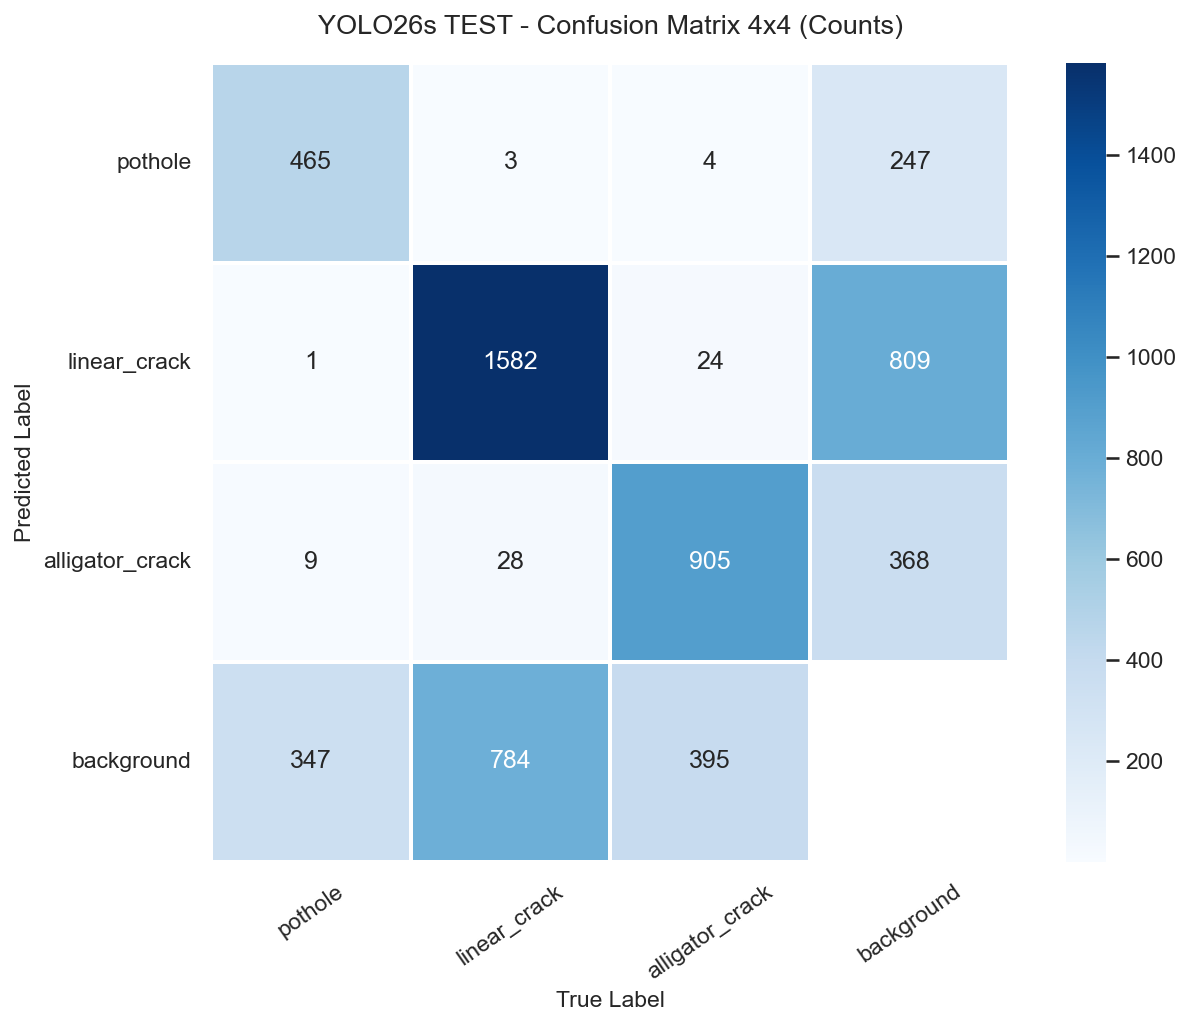

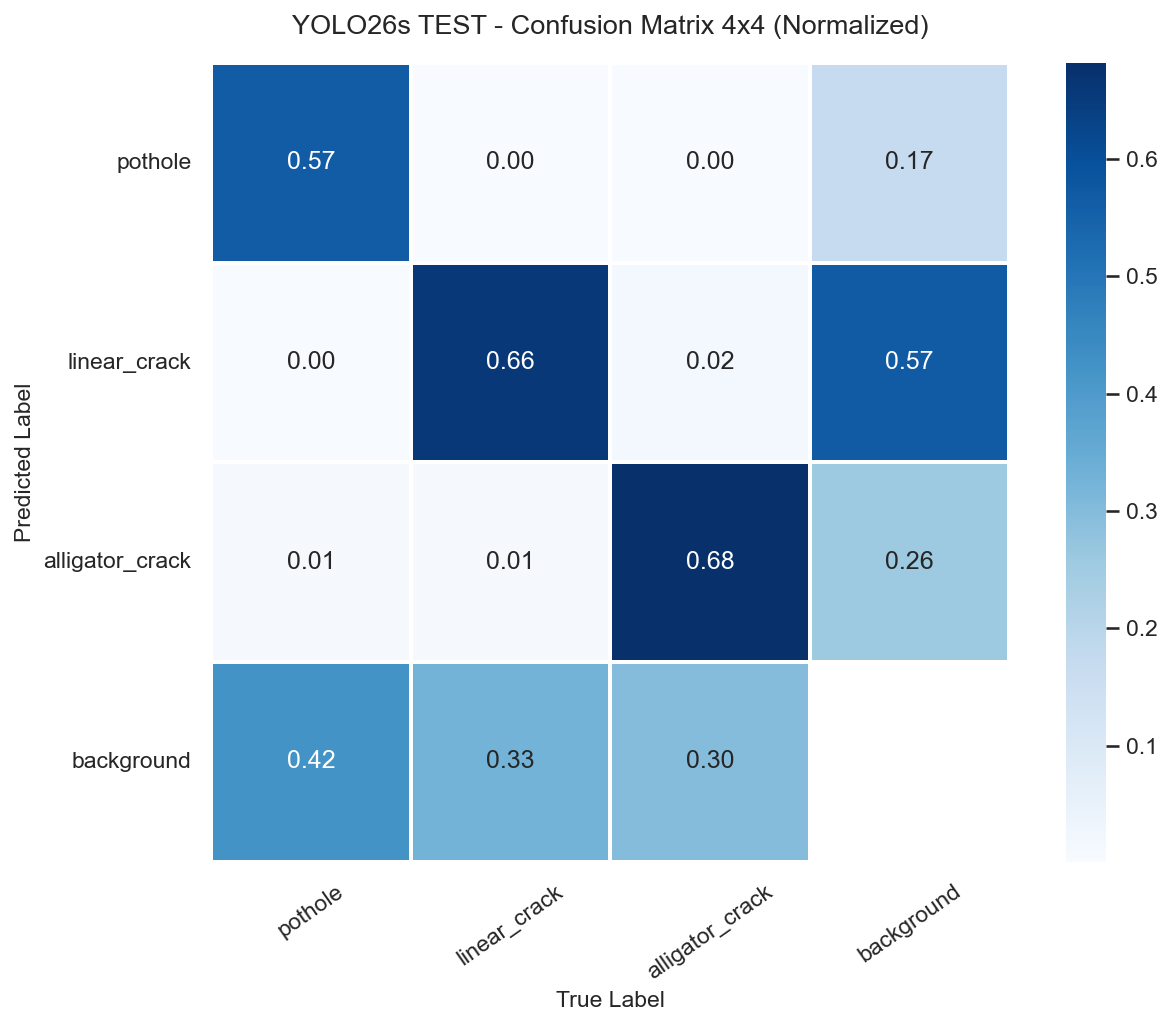

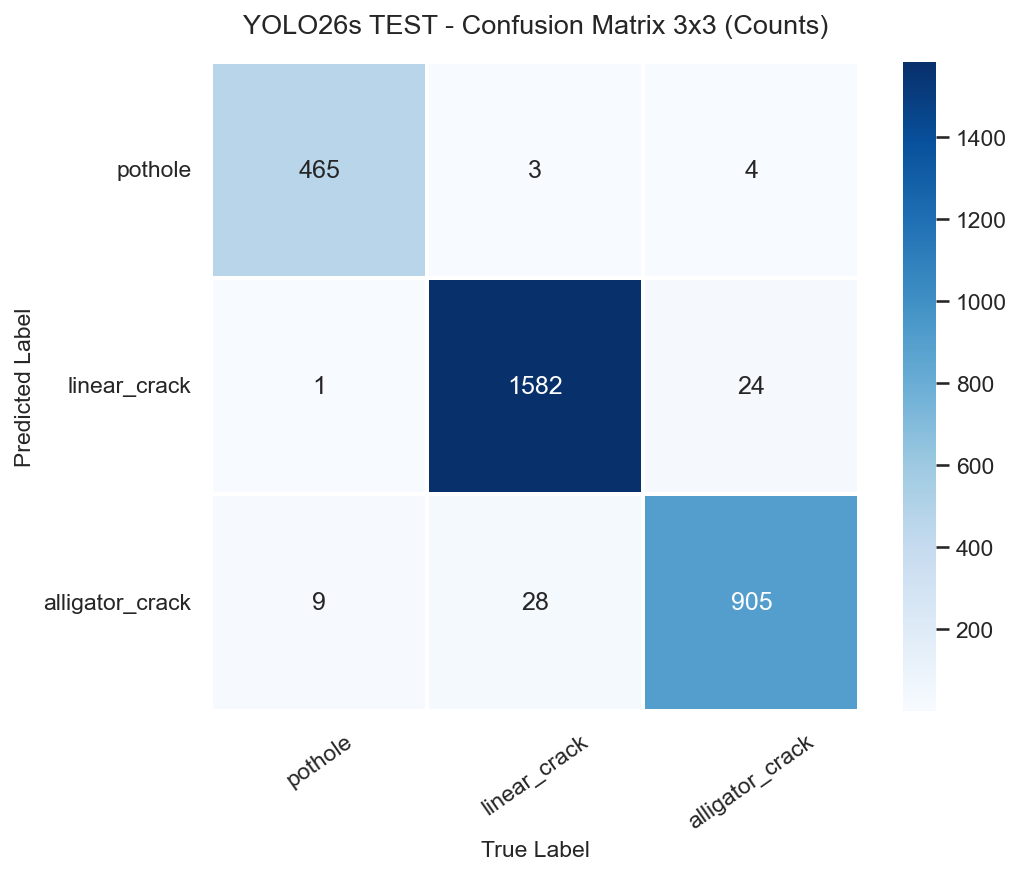

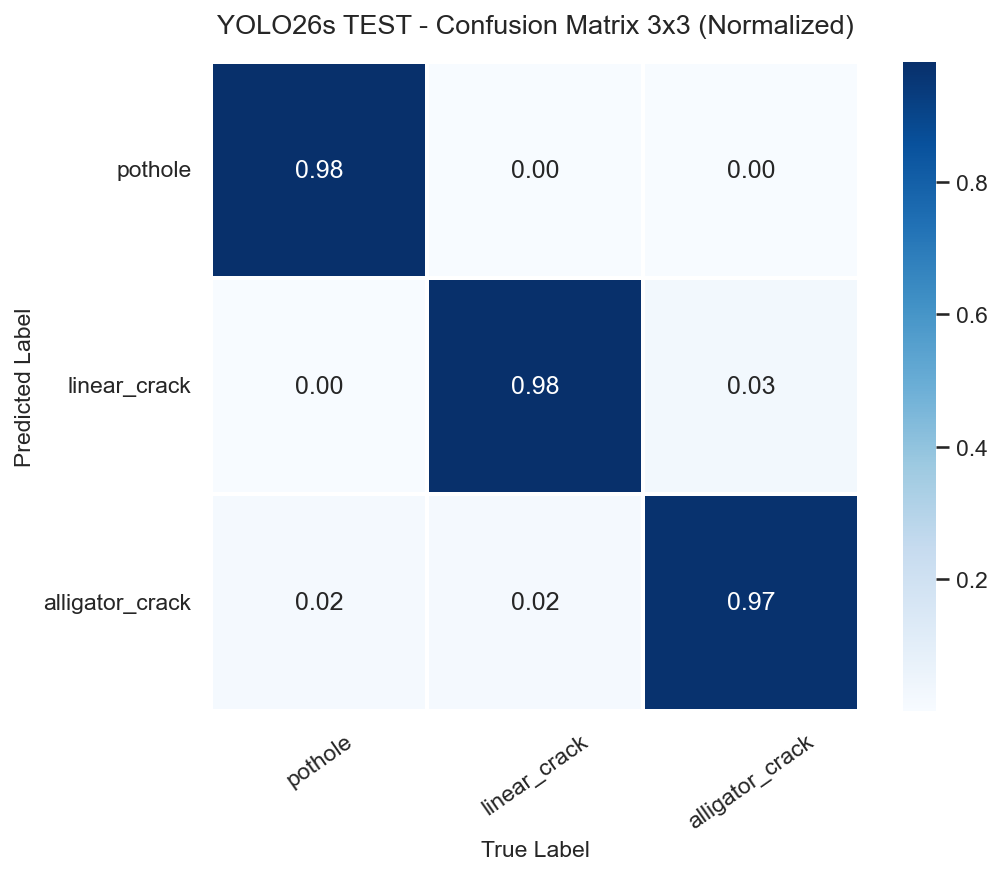


HOÀN THÀNH: 4 PNG + 4 CSV
Thư mục: /kaggle/working/road_damage_analysis/results_yolo26s/confusion_matrices


In [11]:
# ============================================================
# 4 CONFUSION MATRICES - YOLO26s - TEST
# Giữ nguyên logic notebook VAL gốc
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from ultralytics import YOLO

# 1. CẤU HÌNH
CLASS_NAMES = ["pothole", "linear_crack", "alligator_crack"]
FULL_LABELS = CLASS_NAMES + ["background"]
NC = 3

CM_DIR = RESULTS / 'confusion_matrices'
CM_DIR.mkdir(parents=True, exist_ok=True)

# 2. ĐÁNH GIÁ TRÊN TEST - GIỐNG VAL GỐC
cm_model = YOLO(str(MODEL_PATH))

metrics_cm = cm_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    plots=True,
    conf=CONF,
    iou=NMS_IOU,
    nms=True,
    agnostic_nms=False,
    project=str(CM_DIR),
    name="test_evaluation",
    exist_ok=True,
    verbose=False
)

raw_matrix = np.asarray(
    metrics_cm.confusion_matrix.matrix
).copy().astype(float)

print("Ma trận gốc:")
print(raw_matrix)
print("Tổng:", raw_matrix.sum())

assert raw_matrix.shape == (4, 4), "Ma trận không phải 4x4!"
assert raw_matrix.sum() > 0, "Ma trận rỗng, không được xuất!"

# Kiểm tra số lượng GT để tránh dùng nhầm tập dữ liệu
gt_by_class = raw_matrix[:, :NC].sum(axis=0)

print("GT theo từng lớp:", gt_by_class.astype(int))
print("Tổng GT:", int(gt_by_class.sum()))

# Ultralytics loại 1 bounding box bị trùng trong tập test
EXPECTED_GT_AFTER_DEDUP = 4547

assert int(gt_by_class.sum()) == EXPECTED_GT_AFTER_DEDUP, (
    f"GT không khớp: {int(gt_by_class.sum())} "
    f"!= {EXPECTED_GT_AFTER_DEDUP}"
)

print("PASS: 4547 box hợp lệ sau khi loại 1 nhãn trùng.")

# 3. TẠO 4 MA TRẬN ĐÚNG LOGIC VAL

# A. 4x4 Counts
cm_4x4_counts = raw_matrix.copy()
cm_4x4_counts[NC, NC] = np.nan

# B. 4x4 Normalized - theo cột
col_sums_4 = raw_matrix.sum(axis=0, keepdims=True)

cm_4x4_norm = np.divide(
    raw_matrix,
    col_sums_4,
    out=np.zeros_like(raw_matrix),
    where=(col_sums_4 != 0)
)
cm_4x4_norm[NC, NC] = np.nan

# C. 3x3 Counts - bỏ background
cm_3x3_counts = raw_matrix[:NC, :NC].copy()

# D. 3x3 Normalized - theo cột
col_sums_3 = cm_3x3_counts.sum(axis=0, keepdims=True)

cm_3x3_norm = np.divide(
    cm_3x3_counts,
    col_sums_3,
    out=np.zeros_like(cm_3x3_counts),
    where=(col_sums_3 != 0)
)

# 4. VẼ VÀ LƯU 4 MA TRẬN
sns.set_theme(style="white", font_scale=1.0)

matrix_tasks = [
    (cm_4x4_counts, FULL_LABELS, ".0f",
     "YOLO26s TEST - Confusion Matrix 4x4 (Counts)",
     "confusion_matrix_4x4_counts"),

    (cm_4x4_norm, FULL_LABELS, ".2f",
     "YOLO26s TEST - Confusion Matrix 4x4 (Normalized)",
     "confusion_matrix_4x4_normalized"),

    (cm_3x3_counts, CLASS_NAMES, ".0f",
     "YOLO26s TEST - Confusion Matrix 3x3 (Counts)",
     "confusion_matrix_3x3_counts"),

    (cm_3x3_norm, CLASS_NAMES, ".2f",
     "YOLO26s TEST - Confusion Matrix 3x3 (Normalized)",
     "confusion_matrix_3x3_normalized")
]

for cm, labels, fmt, title, filename in matrix_tasks:

    # Lưu CSV
    pd.DataFrame(
        cm,
        index=labels,
        columns=labels
    ).to_csv(
        CM_DIR / f"{filename}.csv",
        encoding="utf-8-sig"
    )

    # Vẽ giống notebook VAL
    fig_size = (9, 7) if len(labels) == 4 else (7.5, 6)
    fig, ax = plt.subplots(figsize=fig_size, dpi=150)

    sns.heatmap(
        cm,
        annot=True,
        fmt=fmt,
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        cbar=True,
        square=True,
        linewidths=1,
        linecolor="white",
        ax=ax
    )

    ax.set_title(title, fontsize=13, fontweight="bold", pad=14)
    ax.set_xlabel("True Label", fontsize=11, fontweight="bold")
    ax.set_ylabel("Predicted Label", fontsize=11, fontweight="bold")

    ax.tick_params(axis="x", labelrotation=35)
    ax.tick_params(axis="y", labelrotation=0)

    fig.tight_layout()
    fig.savefig(
        CM_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

print("\nHOÀN THÀNH: 4 PNG + 4 CSV")
print("Thư mục:", CM_DIR)

### Cell 7 — Biểu đồ, PDF và ảnh lỗi
Tạo báo cáo định lượng, biểu đồ 0–3 loại hư hỏng và các tổ hợp lớp.
Xuất riêng ảnh minh họa 6 trường hợp có nhiều lỗi nhất để kiểm tra trực quan.


In [12]:
from matplotlib.backends.backend_pdf import PdfPages
plt.rcParams['font.family']='DejaVu Sans'
PDF_PATH=RESULTS/'yolo26s_test_report.pdf'
with PdfPages(PDF_PATH) as pdf:
    fig,ax=plt.subplots(figsize=(11,8.5));ax.axis('off')
    lines=['YOLO26s - RDD2022 TEST REPORT','',f'Test images: {len(test_images):,}',
           f'GT bounding boxes: {len(df_gt):,}',f'Predicted boxes (conf >= {CONF}): {len(df_pred):,}',
           f'Precision: {metric_summary["precision"]:.4f}',f'Recall: {metric_summary["recall"]:.4f}',
           f'mAP50: {metric_summary["mAP50"]:.4f}',f'mAP50-95: {metric_summary["mAP50_95"]:.4f}',
           '',f'Exact image-level class-set rate: {df_eval.exact_class_set.mean():.4f}',
           f'All true damage types localized @IoU50: {df_eval.all_true_types_localized.mean():.4f}',
           '', 'Note: images grouped by GROUND TRUTH, not by prediction.',
           'Model selection and thresholds must be determined before test evaluation.']
    ax.text(.07,.94,'\n'.join(lines),transform=ax.transAxes,va='top',fontsize=14,linespacing=1.7)
    pdf.savefig(fig,bbox_inches='tight');plt.close(fig)
    fig,ax=plt.subplots(figsize=(11,6))
    x=np.arange(4);width=.35
    ax.bar(x-width/2,df_counts.ground_truth_images,width,label='Ground Truth')
    ax.bar(x+width/2,df_counts.prediction_images,width,label='Prediction')
    ax.set_xticks(x,[str(i) for i in x]);ax.set_xlabel('Number of different damage types per image');ax.set_ylabel('Images')
    ax.set_title('RDD2022 test - damage type diversity');ax.legend();ax.grid(axis='y',alpha=.2)
    pdf.savefig(fig,bbox_inches='tight');fig.savefig(RESULTS/'types_distribution.png',dpi=160,bbox_inches='tight');plt.close(fig)
    fig,ax=plt.subplots(figsize=(11,7))
    y=np.arange(len(df_combo));ax.barh(y-.2,df_combo.ground_truth_images,.4,label='Ground Truth')
    ax.barh(y+.2,df_combo.prediction_images,.4,label='Prediction');ax.set_yticks(y,df_combo.combination)
    ax.invert_yaxis();ax.set_xlabel('Number of images');ax.set_title('Damage combinations');ax.legend()
    fig.tight_layout();pdf.savefig(fig,bbox_inches='tight');fig.savefig(RESULTS/'combinations.png',dpi=160,bbox_inches='tight');plt.close(fig)
    fig,ax=plt.subplots(figsize=(11,6))
    ax.bar(df_counts.number_of_types.astype(str),df_counts.all_types_localized_rate.fillna(0))
    ax.set_ylim(0,1);ax.set_ylabel('Rate');ax.set_xlabel('Ground Truth damage type count')
    ax.set_title('All true classes localized in image (IoU >= 0.50)')
    pdf.savefig(fig,bbox_inches='tight');fig.savefig(RESULTS/'all_types_localized.png',dpi=160,bbox_inches='tight');plt.close(fig)
# Thêm ảnh minh họa để báo cáo không chỉ có bảng số liệu.
from PIL import ImageDraw
EXAMPLE_DIR=RESULTS/'examples'
EXAMPLE_DIR.mkdir(exist_ok=True)
examples=df_eval.sort_values(['fn_boxes_iou50','fp_boxes_iou50'],ascending=False).head(6)
for rank,row in enumerate(examples.itertuples(index=False),1):
    path=TEST_IMG/row.image_id
    with Image.open(path) as im:
        im=im.convert('RGB')
        draw=ImageDraw.Draw(im)
        for g in GT_BY.get(row.image_id,[]):
            draw.rectangle([g[q] for q in ('x1','y1','x2','y2')],outline='lime',width=3)
        for p in PRED_BY.get(row.image_id,[]):
            draw.rectangle([p[q] for q in ('x1','y1','x2','y2')],outline='red',width=3)
        im.thumbnail((1100,800))
        out=EXAMPLE_DIR/f'{rank:02d}_{Path(row.image_id).stem}.jpg'
        im.save(out,quality=88)
# Bổ sung các trang ảnh vào PDF cùng phần chú thích.
with PdfPages(RESULTS/'error_examples.pdf') as pdf:
    for out in sorted(EXAMPLE_DIR.glob('*.jpg')):
        fig,ax=plt.subplots(figsize=(11,8))
        ax.imshow(Image.open(out));ax.axis('off')
        ax.set_title('GT: green | Predictions: red — '+out.name)
        pdf.savefig(fig,bbox_inches='tight');plt.close(fig)
print('Báo cáo PDF:',PDF_PATH)
print('Ví dụ ảnh lỗi:',EXAMPLE_DIR)
print('Lưu ý: báo cáo mẫu được trình bày bằng tiếng Anh để tránh lỗi font tiếng Việt.')

Báo cáo PDF: /kaggle/working/road_damage_analysis/results_yolo26s/yolo26s_test_report.pdf
Ví dụ ảnh lỗi: /kaggle/working/road_damage_analysis/results_yolo26s/examples
Lưu ý: báo cáo mẫu được trình bày bằng tiếng Anh để tránh lỗi font tiếng Việt.


### Cell 8 — Đóng gói và tải kết quả
Đóng gói CSV, JSON, ảnh biểu đồ, ma trận nhầm lẫn và báo cáo PDF thành một file ZIP.
Tải ZIP về máy để lưu dài hạn; không chứa hàng nghìn ảnh gốc hay checkpoint.

In [ ]:
metadata={'model':'YOLO26s','model_path':str(MODEL_PATH),'dataset_images':len(test_images),'ground_truth_boxes':len(df_gt),
          'confidence_for_per_image_report':CONF,'nms_iou':NMS_IOU,'match_iou':MATCH_IOU,
          'model_names':CLASSES,'ultralytics':ultralytics.__version__,
          'checkpoint_selection':'YOLO26s LR 0.000667; path explicitly verified',
          'confusion_matrix_protocol':'model.val(conf=0.25,iou=0.45,nms=True,agnostic_nms=False)',
          'note':'Test metrics for final evaluation; do not use test to choose hyperparameters. Per-image matching is greedy IoU50 at conf=0.25, not COCO-mAP. No cross-model recommendation until YOLO26s is evaluated.'}
(RESULTS/'run_metadata.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False),encoding='utf-8')
ZIP=shutil.make_archive('/kaggle/working/yolo26s_rdd2022_test_statistics','zip',root_dir=str(RESULTS))
print('ĐÃ XUẤT:',ZIP,'Size (MB):',round(Path(ZIP).stat().st_size/1024**2,2))
display(FileLink(ZIP))

ĐÃ XUẤT: /kaggle/working/yolo26s_rdd2022_test_statistics.zip Size (MB): 13.75


/kaggle/working/yolo26s_rdd2022_test_statistics.zip

## PHẦN BỔ SUNG — TEST YOLO26n TRÊN CÙNG DỮ LIỆU (NMS = 0,45)

**Không chạy lại Cell 2 dựng dữ liệu.** Nếu đã chạy các cell YOLO26s phía trên trong **cùng một phiên Kaggle**, chạy tiếp các cell YOLO26n bên dưới. Cần gắn **model `best.pt` của YOLO26n** trong panel Kaggle **Input → Models** trước.

- Dùng lại `TEST_IMG`, `TEST_LBL`, `DATA_YAML`, `test_images`, `df_gt`, `df_gt_imgs` đã tạo một lần ở Cell 2–3.
- YOLO26n sẽ dùng `conf=0.25`, **NMS IoU = 0.45**, NMS theo lớp, **IoU ghép GT = 0.50**, `imgsz=640`.
- Không huấn luyện lại; YOLO26s và YOLO26n **lưu ra các thư mục riêng**.
- Phần `model.val()` tính mAP chính thức vẫn để **tham số đánh giá mặc định**, không đồng nhất với phân tích từng ảnh.

**Nếu vừa mở Kaggle Session mới:** phải chạy lại các cell cài đặt, chuẩn bị dữ liệu và đọc Ground Truth (Cell 1–3) *hoặc nạp bộ Test đã lưu sẵn*. Không thể tái sử dụng thư mục `/kaggle/working` từ một session đã đóng.


In [14]:
# Cell N1 — Khởi tạo YOLO26n, TÁI SỬ DỤNG tập Test và Ground Truth hiện có
from pathlib import Path
import shutil, json, time
from collections import Counter
import pandas as pd
import numpy as np
from ultralytics import YOLO

needed = ['TEST_IMG','TEST_LBL','DATA_YAML','test_images','df_gt','df_gt_imgs',
          'CLASSES','CONF','NMS_IOU','MATCH_IOU','IMGSZ','BATCH','DEVICE','ROOT']
missing_vars = [v for v in needed if v not in globals()]
assert not missing_vars, (
    f'Thiếu biến: {missing_vars}. Hãy chạy các cell cấu hình + dựng dữ liệu + Ground Truth (Cell 1–3) trước.')
assert len(test_images) == 2196, f'Test phải có 2196 ảnh, hiện là {len(test_images)}'
assert len(df_gt) == 4548, f'Test phải có 4548 box GT trước loại trùng, hiện là {len(df_gt)}'
assert len(df_gt_imgs) == len(test_images) and df_gt_imgs.image_id.is_unique
assert Path(DATA_YAML).exists() and Path(TEST_IMG).exists() and Path(TEST_LBL).exists()
assert abs(CONF - 0.25) < 1e-8 and abs(NMS_IOU - 0.45) < 1e-8 and abs(MATCH_IOU - 0.50) < 1e-8, (
    'Ngưỡng chưa thống nhất: cần CONF=0.25; NMS_IOU=0.45; MATCH_IOU=0.50')

# Tìm đúng checkpoint YOLO26n theo TÊN TỆP, không suy đoán đường dẫn owner/slug.
N_MODEL_NAME = 'yolo26n_rdd_3class_best.pt'
all_n_named = sorted(p for p in Path('/kaggle/input').rglob(N_MODEL_NAME) if p.is_file())
print('Các checkpoint YOLO26n:', *map(str, all_n_named), sep='\n - ')
assert len(all_n_named) == 1, (
    f'Cần đúng một file {N_MODEL_NAME}. Tìm thấy: {all_n_named}. '
    'Hãy kiểm tra Kaggle Input → Models (Best.pt of yolo26n).'
)
MODEL_PATH_N = all_n_named[0]
assert 'yolo26n' in str(MODEL_PATH_N).lower(), f'Sai checkpoint YOLO26n: {MODEL_PATH_N}'
print('ĐÃ CHỌN YOLO26n:', MODEL_PATH_N)

model_n = YOLO(str(MODEL_PATH_N))
assert {int(k):str(v) for k,v in model_n.names.items()} == CLASSES, (
    f'Thứ tự lớp trong YOLO26n sai: {model_n.names}')
# Kiểm tra không dùng cùng một file cho hai mô hình.
assert MODEL_PATH_N.resolve() != Path(MODEL_PATH).resolve(), 'Hai mô hình đang trỏ cùng một checkpoint!'
print('YOLO26s checkpoint:', MODEL_PATH)
print('YOLO26n checkpoint:', MODEL_PATH_N)

RESULTS_N = ROOT / 'results_yolo26n'
RESULTS_N.mkdir(parents=True, exist_ok=True)
CM_DIR_N = RESULTS_N / 'confusion_matrices'
CM_DIR_N.mkdir(parents=True, exist_ok=True)

# Không xây dựng lại dữ liệu. Sao chép thông tin GT/manifest đã có cho ZIP YOLO26n.
df_gt.to_csv(RESULTS_N/'ground_truth_boxes.csv', index=False)
df_gt_imgs.to_csv(RESULTS_N/'ground_truth_images.csv', index=False)
if 'RESULTS' in globals():
    src_result_dir = Path(RESULTS)
    for filename in ('test_manifest.csv', 'duplicate_image_stems_audit.csv'):
        source_file = src_result_dir/filename
        if source_file.is_file() and source_file.resolve() != (RESULTS_N/filename).resolve():
            shutil.copy2(source_file, RESULTS_N/filename)

print('PASS: Dùng lại',len(test_images),'ảnh Test;',len(df_gt),'box GT')
print('Checkpoint YOLO26n:', MODEL_PATH_N)
print('Output YOLO26n:', RESULTS_N)
print('CONF:', CONF, '| NMS IoU:', NMS_IOU, '| Match IoU:', MATCH_IOU)


Các checkpoint YOLO26n:
 - /kaggle/input/models/vtmhhh/yolo26n-lr-0-00067/pytorch/default/1/yolo26n_rdd_3class_best.pt
ĐÃ CHỌN YOLO26n: /kaggle/input/models/vtmhhh/yolo26n-lr-0-00067/pytorch/default/1/yolo26n_rdd_3class_best.pt
YOLO26s checkpoint: /kaggle/input/models/vtmhhh/yolo26s-lr-0-00067-hihi/pytorch/default/1/yolo26s_rdd_3class_best.pt
YOLO26n checkpoint: /kaggle/input/models/vtmhhh/yolo26n-lr-0-00067/pytorch/default/1/yolo26n_rdd_3class_best.pt
PASS: Dùng lại 2196 ảnh Test; 4548 box GT
Checkpoint YOLO26n: /kaggle/input/models/vtmhhh/yolo26n-lr-0-00067/pytorch/default/1/yolo26n_rdd_3class_best.pt
Output YOLO26n: /kaggle/working/road_damage_analysis/results_yolo26n
CONF: 0.25 | NMS IoU: 0.45 | Match IoU: 0.5


### Cell N2 — YOLO26n: suy luận toàn bộ 2.196 ảnh Test
Cấu hình thống nhất với YOLO26s; `nms=True`, `agnostic_nms=False`. Kết quả lưu riêng vào `results_yolo26n/`.

In [15]:
# Cell N2 — Suy luận YOLO26n (không chạy lại bước tạo dữ liệu)
rows_n=[]; pred_images_n=[]
t0=time.perf_counter()
stream_n=model_n.predict(source=str(TEST_IMG),imgsz=IMGSZ,conf=CONF,iou=NMS_IOU,device=DEVICE,batch=BATCH,nms=True,agnostic_nms=False,stream=True,save=False,verbose=False)
for i,result in enumerate(stream_n,1):
    name=Path(result.path).name
    cls_count=Counter()
    if result.boxes is not None:
        for b in result.boxes:
            c=int(b.cls.item()); score=float(b.conf.item())
            x1,y1,x2,y2=[float(v) for v in b.xyxy[0].tolist()]
            rows_n.append({'image_id':name,'model':'YOLO26n','class_id':c,'class_name':CLASSES[c],
                         'confidence':score,'x1':x1,'y1':y1,'x2':x2,'y2':y2})
            cls_count[c]+=1
    pred_images_n.append({'image_id':name,'model':'YOLO26n','pred_box_count':sum(cls_count.values()),
                        'pred_type_count':len(cls_count),'pred_classes':'|'.join(CLASSES[k] for k in sorted(cls_count)) or 'none',
                        'inference_ms':float(result.speed.get('inference',float('nan'))),
                        'preprocess_ms':float(result.speed.get('preprocess',float('nan'))),
                        'postprocess_ms':float(result.speed.get('postprocess',float('nan'))),
                        **{f'pred_{CLASSES[c]}':cls_count[c] for c in CLASSES}})
    if i%250==0: print(f'Dự đoán {i}/{len(test_images)} ảnh',flush=True)
assert len(pred_images_n)==len(test_images),'Số ảnh đã suy luận không khớp!'
df_pred_n=pd.DataFrame(rows_n,columns=['image_id','model','class_id','class_name','confidence','x1','y1','x2','y2'])
df_pred_imgs_n=pd.DataFrame(pred_images_n)
assert df_pred_imgs_n.image_id.is_unique
df_pred_n.to_csv(RESULTS_N/'predicted_boxes.csv',index=False)
df_pred_imgs_n.to_csv(RESULTS_N/'predicted_images.csv',index=False)
print('Inference xong:',len(pred_images_n),'ảnh; ',len(df_pred_n),'boxes; thời gian tổng:',round(time.perf_counter()-t0,1),'s')

Dự đoán 250/2196 ảnh
Dự đoán 500/2196 ảnh
Dự đoán 750/2196 ảnh
Dự đoán 1000/2196 ảnh
Dự đoán 1250/2196 ảnh
Dự đoán 1500/2196 ảnh
Dự đoán 1750/2196 ảnh
Dự đoán 2000/2196 ảnh
Inference xong: 2196 ảnh;  3896 boxes; thời gian tổng: 15.6 s


### Cell N3 — YOLO26n: thống kê theo từng ảnh và ghép box với GT
Tính Exact Class Set Rate, All Types Localized Rate, TP/FP/FN theo IoU ≥ 0,50 và bảng thống kê 1/2/3 loại. Quy tắc giống phần YOLO26s.

In [16]:
# Cell N3 — Phân tích ảnh theo cùng quy tắc với YOLO26s
def bbox_iou_n(a,b):
    xa=max(a[0],b[0]); ya=max(a[1],b[1]); xb=min(a[2],b[2]); yb=min(a[3],b[3])
    inter=max(xb-xa,0)*max(yb-ya,0)
    area_a=max(a[2]-a[0],0)*max(a[3]-a[1],0)
    area_b=max(b[2]-b[0],0)*max(b[3]-b[1],0)
    return inter/(area_a+area_b-inter) if (area_a+area_b-inter)>0 else 0.0

GT_BY_N={k:g.to_dict('records') for k,g in df_gt.groupby('image_id')}
PRED_BY_N={k:g.to_dict('records') for k,g in df_pred_n.groupby('image_id')} if len(df_pred_n) else {}
image_evals_n=[]; match_rows_n=[]; error_boxes_n=[]
for name in df_gt_imgs.image_id:
    gg=GT_BY_N.get(name,[]); pp=PRED_BY_N.get(name,[])
    # greedy IoU one-to-one within the same class, ưu tiên IoU cao nhất
    candidates=[]
    for gi,g in enumerate(gg):
        for pi,p in enumerate(pp):
            if g['class_id']!=p['class_id']: continue
            iou=bbox_iou_n([g[q] for q in ('x1','y1','x2','y2')],[p[q] for q in ('x1','y1','x2','y2')])
            if iou>=MATCH_IOU: candidates.append((iou,gi,pi))
    matched_g=set(); matched_p=set()
    for iou,gi,pi in sorted(candidates,reverse=True):
        if gi in matched_g or pi in matched_p: continue
        matched_g.add(gi); matched_p.add(pi)
        match_rows_n.append({'image_id':name,'class_id':gg[gi]['class_id'],'iou':iou,'gt_id':gg[gi]['gt_id'],'confidence':pp[pi]['confidence']})
    for gi,g in enumerate(gg):
        if gi not in matched_g:
            error_boxes_n.append({'image_id':name,'error_type':'FN','class_id':g['class_id'],
                'class_name':CLASSES[g['class_id']],**{q:g[q] for q in ('x1','y1','x2','y2')},'confidence':None})
    for pi,p in enumerate(pp):
        if pi not in matched_p:
            error_boxes_n.append({'image_id':name,'error_type':'FP','class_id':p['class_id'],
                'class_name':CLASSES[p['class_id']],**{q:p[q] for q in ('x1','y1','x2','y2')},'confidence':p['confidence']})
    real=set(g['class_id'] for g in gg); detected=set(p['class_id'] for p in pp)
    correctly_detected={gg[gi]['class_id'] for gi in matched_g}
    image_evals_n.append({'image_id':name,'gt_type_count':len(real),'pred_type_count':len(detected),
        'gt_combination':' + '.join(CLASSES[i] for i in sorted(real)) or 'none',
        'pred_combination':' + '.join(CLASSES[i] for i in sorted(detected)) or 'none',
        'exact_class_set':int(real==detected),
        'all_true_types_localized':int(real.issubset(correctly_detected)),
        'all_gt_boxes_detected':int(len(matched_g)==len(gg)),
        'tp_boxes_iou50':len(matched_g),'fn_boxes_iou50':len(gg)-len(matched_g),'fp_boxes_iou50':len(pp)-len(matched_p),
        'image_class_set_recall':len(correctly_detected)/len(real) if real else 1.0})
df_eval_n=pd.DataFrame(image_evals_n)
df_matches_n=pd.DataFrame(match_rows_n,columns=['image_id','class_id','iou','gt_id','confidence'])
df_eval_n.to_csv(RESULTS_N/'per_image_analysis.csv',index=False)
df_matches_n.to_csv(RESULTS_N/'matched_boxes_iou50.csv',index=False)
df_errors_n=pd.DataFrame(error_boxes_n,columns=['image_id','error_type','class_id','class_name','x1','y1','x2','y2','confidence'])
df_errors_n.to_csv(RESULTS_N/'unmatched_boxes_fp_fn.csv',index=False)
cls_err_n=[]
for c in CLASSES:
    fn=int(((df_errors_n.error_type=='FN') & (df_errors_n.class_id==c)).sum())
    fp=int(((df_errors_n.error_type=='FP') & (df_errors_n.class_id==c)).sum())
    tp=int((df_matches_n.class_id==c).sum())
    cls_err_n.append({'class_id':c,'class_name':CLASSES[c],'TP_IoU50':tp,'FP_IoU50':fp,'FN_IoU50':fn,
                    'precision_iou50_at_report_conf':tp/(tp+fp) if tp+fp else None,
                    'recall_iou50_at_report_conf':tp/(tp+fn) if tp+fn else None})
df_class_error_n=pd.DataFrame(cls_err_n)
df_class_error_n.to_csv(RESULTS_N/'per_class_tp_fp_fn.csv',index=False)
all_combos_n=['none']+[' + '.join(CLASSES[c] for c in xs) for k in (1,2,3) for xs in combinations(CLASSES,k)]
df_combo_n=pd.DataFrame({'combination':all_combos_n,
   'ground_truth_images':[int((df_eval_n.gt_combination==c).sum()) for c in all_combos_n],
   'prediction_images':[int((df_eval_n.pred_combination==c).sum()) for c in all_combos_n]})
df_counts_n=pd.DataFrame([{'number_of_types':i,
   'ground_truth_images':int((df_eval_n.gt_type_count==i).sum()),
   'prediction_images':int((df_eval_n.pred_type_count==i).sum()),
   'exact_class_set_rate':float(df_eval_n.loc[df_eval_n.gt_type_count==i,'exact_class_set'].mean()) if (df_eval_n.gt_type_count==i).any() else None,
   'all_types_localized_rate':float(df_eval_n.loc[df_eval_n.gt_type_count==i,'all_true_types_localized'].mean()) if (df_eval_n.gt_type_count==i).any() else None}
  for i in range(4)])
df_combo_n.to_csv(RESULTS_N/'combination_summary.csv',index=False)
df_counts_n.to_csv(RESULTS_N/'type_count_summary.csv',index=False)
print('Số loại trong ảnh:'); display(df_counts_n)
print('Tổ hợp lớp:');display(df_combo_n)
print('Tổng TP/FN/FP @IoU50 (tại CONF=0.25):',df_eval_n[['tp_boxes_iou50','fn_boxes_iou50','fp_boxes_iou50']].sum().to_dict())

Số loại trong ảnh:


,number_of_types,ground_truth_images,prediction_images,exact_class_set_rate,all_types_localized_rate
0,0,0,164,NaN,NaN
1,1,1681,1579,0.800119,0.779298
2,2,454,418,0.546256,0.447137
3,3,61,35,0.278689,0.147541


Tổ hợp lớp:


,combination,ground_truth_images,prediction_images
0,none,0,164
1,pothole,195,203
2,linear_crack,915,839
3,alligator_crack,571,537
4,pothole + linear_crack,48,44
5,pothole + alligator_crack,147,131
6,linear_crack + alligator_crack,259,243
7,pothole + linear_crack + alligator_crack,61,35


Tổng TP/FN/FP @IoU50 (tại CONF=0.25): {'tp_boxes_iou50': 2722, 'fn_boxes_iou50': 1826, 'fp_boxes_iou50': 1174}


### Cell N4 — YOLO26n: đánh giá Precision, Recall, mAP chính thức
**Chú ý:** `val()` không khai báo ngưỡng 0,25/0,45 ở đây, để giữ nguyên giao thức tính mAP chính thức như YOLO26s.

In [17]:
# Cell N4 — mAP Test chính thức (mặc định Ultralytics)
metrics_n=model_n.val(data=str(DATA_YAML),split='test',imgsz=IMGSZ,batch=BATCH,device=DEVICE,plots=True,
                  project=str(RESULTS_N),name='ultralytics_test',exist_ok=True,verbose=False)
metric_summary_n={'model':'YOLO26n','checkpoint':str(MODEL_PATH_N),'num_images':len(test_images),
                'precision':float(metrics_n.box.mp),'recall':float(metrics_n.box.mr),
                'mAP50':float(metrics_n.box.map50),'mAP50_95':float(metrics_n.box.map),
                'ultralytics_version':ultralytics.__version__,'imgsz':IMGSZ,
                'report_confidence_threshold':CONF,'report_nms_iou':NMS_IOU,'box_matching_iou':MATCH_IOU}
per_class_n=[]
# metrics_n.box.maps là AP50-95 mỗi class theo thứ tự id 0..nc-1
for c,ap in enumerate(metrics_n.box.maps):
    per_class_n.append({'class_id':c,'class_name':CLASSES[c],'AP50_95':float(ap)})
pd.DataFrame(per_class_n).to_csv(RESULTS_N/'per_class_ap.csv',index=False)
(RESULTS_N/'metrics.json').write_text(json.dumps(metric_summary_n,indent=2,ensure_ascii=False),encoding='utf-8')
print(json.dumps(metric_summary_n,indent=2,ensure_ascii=False))
display(pd.DataFrame(per_class_n))

Ultralytics 8.4.213 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 123.8±64.4 MB/s, size: 69.9 KB)
val: Scanning /kaggle/working/dataset_3class/test/labels.cache... 2196 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2196/2196 400.5Mit/s 0.0s
val: /kaggle/working/dataset_3class/test/images/Japan_002934.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 138/138 6.9it/s 20.0s0.1s
                   all       2196       4547      0.681      0.595      0.649      0.328
Speed: 1.0ms preprocess, 3.7ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /kaggle/working/road_damage_analysis/results_yolo26n/ultralytics_test
{
  "model": "YOLO26n",
  "checkpoint": "/kaggle/input/models/vtmhhh/yolo26n-lr-0-00067/pytorch/default/1/yolo26n_rdd

,class_id,class_name,AP50_95
0,0,pothole,0.255935
1,1,linear_crack,0.362888
2,2,alligator_crack,0.365630


### Cell N5 — YOLO26n: ma trận nhầm lẫn 4×4, `conf=0,25`, `NMS IoU=0,45`
Xuất 4×4 counts/normalized và 3×3 counts/normalized (CSV + PNG) giống YOLO26s. **Ma trận này là giao thức khác với mAP chính thức**.

Ultralytics 8.4.213 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 106.5±33.0 MB/s, size: 75.0 KB)
val: Scanning /kaggle/working/dataset_3class/test/labels.cache... 2196 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2196/2196 400.5Mit/s 0.0s
val: /kaggle/working/dataset_3class/test/images/Japan_002934.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 138/138 7.2it/s 19.3s0.1s
                   all       2196       4547      0.677      0.616      0.547       0.28
Speed: 1.0ms preprocess, 3.7ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/road_damage_analysis/results_yolo26n/confusion_matrices/test_evaluation
Ma trận gốc:
[[        452           4           5         240]
 [          1        1510          

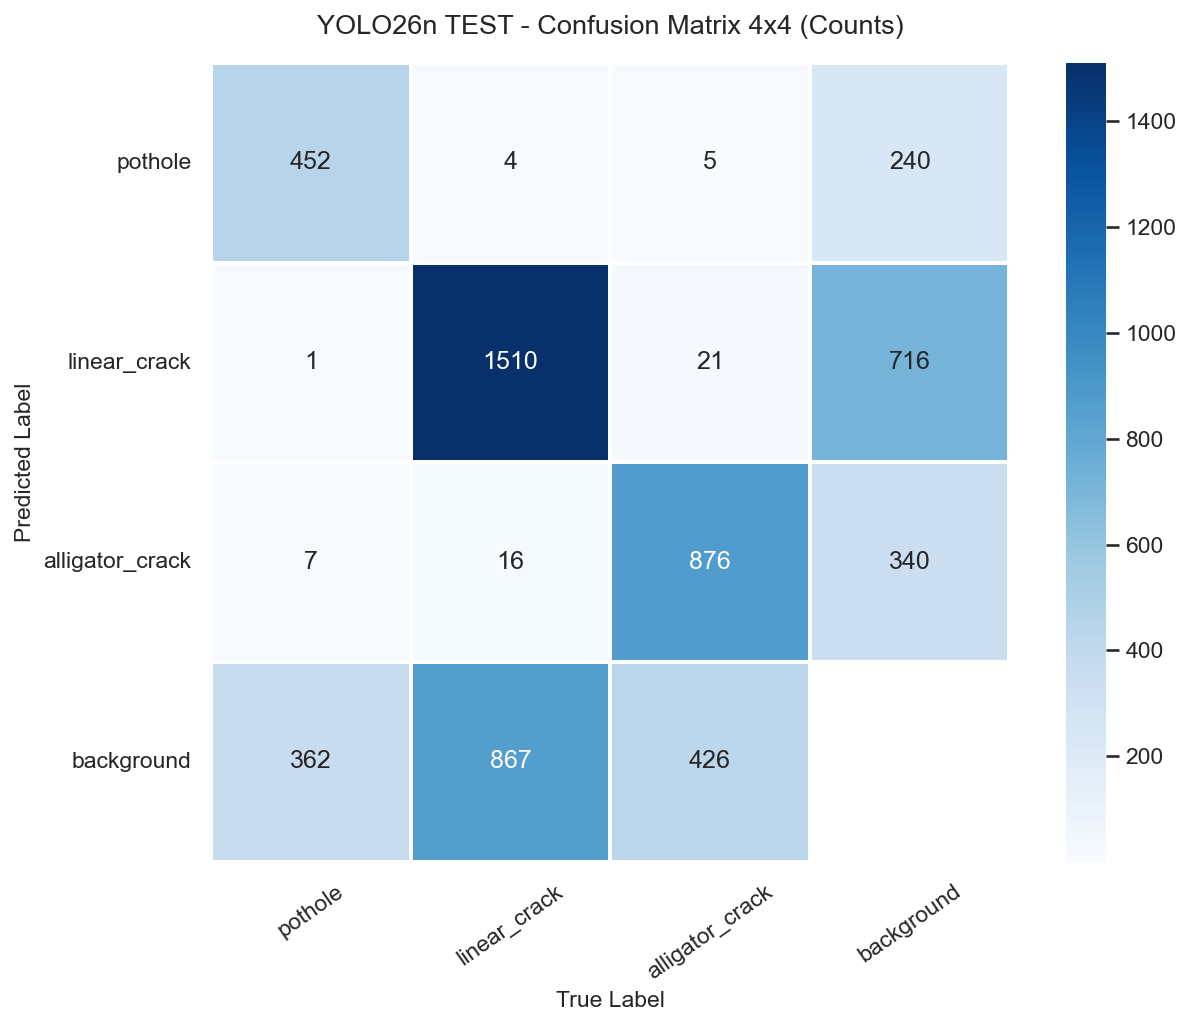

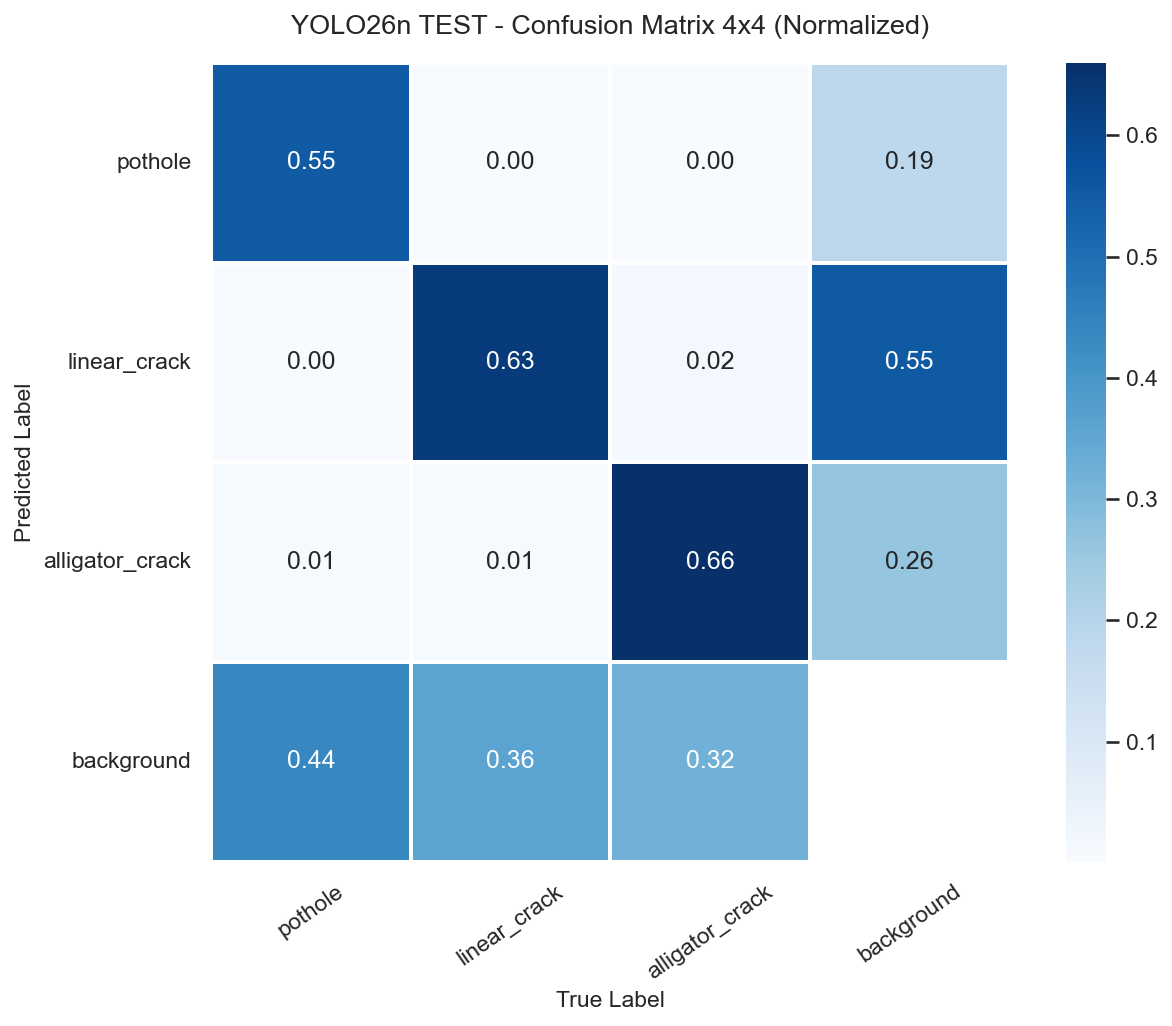

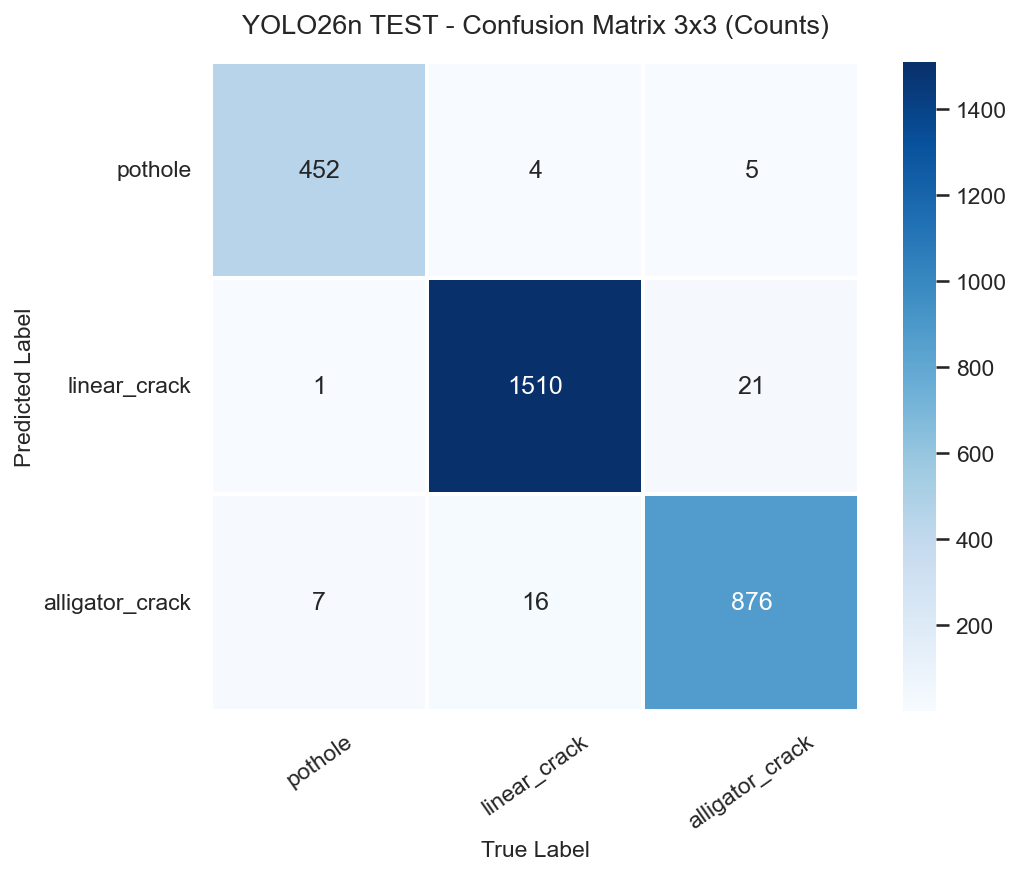

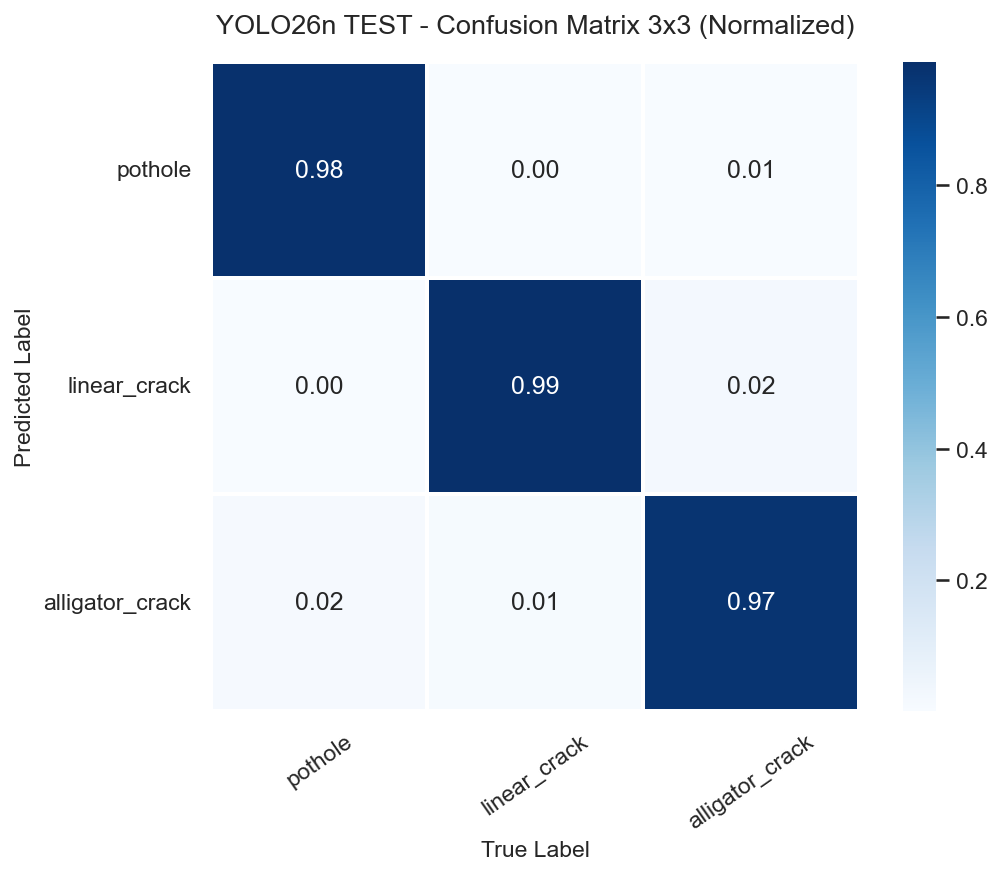


HOÀN THÀNH: 4 PNG + 4 CSV
Thư mục: /kaggle/working/road_damage_analysis/results_yolo26n/confusion_matrices


In [18]:
# ============================================================
# 4 CONFUSION MATRICES - YOLO26n - TEST
# Giữ nguyên logic notebook VAL gốc
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from ultralytics import YOLO

# 1. CẤU HÌNH
CLASS_NAMES = ["pothole", "linear_crack", "alligator_crack"]
FULL_LABELS = CLASS_NAMES + ["background"]
NC = 3

CM_DIR_N = RESULTS_N / 'confusion_matrices'
CM_DIR_N.mkdir(parents=True, exist_ok=True)

# 2. ĐÁNH GIÁ TRÊN TEST - GIỐNG VAL GỐC
cm_model_n = YOLO(str(MODEL_PATH_N))

metrics_cm_n = cm_model_n.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    plots=True,
    conf=CONF,
    iou=NMS_IOU,
    nms=True,
    agnostic_nms=False,
    project=str(CM_DIR_N),
    name="test_evaluation",
    exist_ok=True,
    verbose=False
)

raw_matrix_n = np.asarray(
    metrics_cm_n.confusion_matrix.matrix
).copy().astype(float)

print("Ma trận gốc:")
print(raw_matrix_n)
print("Tổng:", raw_matrix_n.sum())

assert raw_matrix_n.shape == (4, 4), "Ma trận không phải 4x4!"
assert raw_matrix_n.sum() > 0, "Ma trận rỗng, không được xuất!"

# Kiểm tra số lượng GT để tránh dùng nhầm tập dữ liệu
gt_by_class = raw_matrix_n[:, :NC].sum(axis=0)

print("GT theo từng lớp:", gt_by_class.astype(int))
print("Tổng GT:", int(gt_by_class.sum()))

# Ultralytics loại 1 bounding box bị trùng trong tập test
EXPECTED_GT_AFTER_DEDUP = 4547

assert int(gt_by_class.sum()) == EXPECTED_GT_AFTER_DEDUP, (
    f"GT không khớp: {int(gt_by_class.sum())} "
    f"!= {EXPECTED_GT_AFTER_DEDUP}"
)

print("PASS: 4547 box hợp lệ sau khi loại 1 nhãn trùng.")

# 3. TẠO 4 MA TRẬN ĐÚNG LOGIC VAL

# A. 4x4 Counts
cm_4x4_counts_n = raw_matrix_n.copy()
cm_4x4_counts_n[NC, NC] = np.nan

# B. 4x4 Normalized - theo cột
col_sums_4_n = raw_matrix_n.sum(axis=0, keepdims=True)

cm_4x4_norm_n = np.divide(
    raw_matrix_n,
    col_sums_4_n,
    out=np.zeros_like(raw_matrix_n),
    where=(col_sums_4_n != 0)
)
cm_4x4_norm_n[NC, NC] = np.nan

# C. 3x3 Counts - bỏ background
cm_3x3_counts_n = raw_matrix_n[:NC, :NC].copy()

# D. 3x3 Normalized - theo cột
col_sums_3_n = cm_3x3_counts_n.sum(axis=0, keepdims=True)

cm_3x3_norm_n = np.divide(
    cm_3x3_counts_n,
    col_sums_3_n,
    out=np.zeros_like(cm_3x3_counts_n),
    where=(col_sums_3_n != 0)
)

# 4. VẼ VÀ LƯU 4 MA TRẬN
sns.set_theme(style="white", font_scale=1.0)

matrix_tasks_n = [
    (cm_4x4_counts_n, FULL_LABELS, ".0f",
     "YOLO26n TEST - Confusion Matrix 4x4 (Counts)",
     "confusion_matrix_4x4_counts"),

    (cm_4x4_norm_n, FULL_LABELS, ".2f",
     "YOLO26n TEST - Confusion Matrix 4x4 (Normalized)",
     "confusion_matrix_4x4_normalized"),

    (cm_3x3_counts_n, CLASS_NAMES, ".0f",
     "YOLO26n TEST - Confusion Matrix 3x3 (Counts)",
     "confusion_matrix_3x3_counts"),

    (cm_3x3_norm_n, CLASS_NAMES, ".2f",
     "YOLO26n TEST - Confusion Matrix 3x3 (Normalized)",
     "confusion_matrix_3x3_normalized")
]

for cm, labels, fmt, title, filename in matrix_tasks_n:

    # Lưu CSV
    pd.DataFrame(
        cm,
        index=labels,
        columns=labels
    ).to_csv(
        CM_DIR_N / f"{filename}.csv",
        encoding="utf-8-sig"
    )

    # Vẽ giống notebook VAL
    fig_size = (9, 7) if len(labels) == 4 else (7.5, 6)
    fig, ax = plt.subplots(figsize=fig_size, dpi=150)

    sns.heatmap(
        cm,
        annot=True,
        fmt=fmt,
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        cbar=True,
        square=True,
        linewidths=1,
        linecolor="white",
        ax=ax
    )

    ax.set_title(title, fontsize=13, fontweight="bold", pad=14)
    ax.set_xlabel("True Label", fontsize=11, fontweight="bold")
    ax.set_ylabel("Predicted Label", fontsize=11, fontweight="bold")

    ax.tick_params(axis="x", labelrotation=35)
    ax.tick_params(axis="y", labelrotation=0)

    fig.tight_layout()
    fig.savefig(
        CM_DIR_N / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

print("\nHOÀN THÀNH: 4 PNG + 4 CSV")
print("Thư mục:", CM_DIR_N)

### Cell N6 — YOLO26n: biểu đồ, PDF và ví dụ ảnh lỗi
Sử dụng cùng các bảng kết quả YOLO26n đã tạo, không ghi đè PDF/hình của YOLO26s.

In [19]:
# Cell N6 — PDF và hình ảnh lỗi cho YOLO26n
from matplotlib.backends.backend_pdf import PdfPages
plt.rcParams['font.family']='DejaVu Sans'
PDF_PATH_N=RESULTS_N/'yolo26n_test_report.pdf'
with PdfPages(PDF_PATH_N) as pdf:
    fig,ax=plt.subplots(figsize=(11,8.5));ax.axis('off')
    lines=['YOLO26n - RDD2022 TEST REPORT','',f'Test images: {len(test_images):,}',
           f'GT bounding boxes: {len(df_gt):,}',f'Predicted boxes (conf >= {CONF}): {len(df_pred_n):,}',
           f'Precision: {metric_summary_n["precision"]:.4f}',f'Recall: {metric_summary_n["recall"]:.4f}',
           f'mAP50: {metric_summary_n["mAP50"]:.4f}',f'mAP50-95: {metric_summary_n["mAP50_95"]:.4f}',
           '',f'Exact image-level class-set rate: {df_eval_n.exact_class_set.mean():.4f}',
           f'All true damage types localized @IoU50: {df_eval_n.all_true_types_localized.mean():.4f}',
           '', 'Note: images grouped by GROUND TRUTH, not by prediction.',
           'Model selection and thresholds must be determined before test evaluation.']
    ax.text(.07,.94,'\n'.join(lines),transform=ax.transAxes,va='top',fontsize=14,linespacing=1.7)
    pdf.savefig(fig,bbox_inches='tight');plt.close(fig)
    fig,ax=plt.subplots(figsize=(11,6))
    x=np.arange(4);width=.35
    ax.bar(x-width/2,df_counts_n.ground_truth_images,width,label='Ground Truth')
    ax.bar(x+width/2,df_counts_n.prediction_images,width,label='Prediction')
    ax.set_xticks(x,[str(i) for i in x]);ax.set_xlabel('Number of different damage types per image');ax.set_ylabel('Images')
    ax.set_title('RDD2022 test - damage type diversity');ax.legend();ax.grid(axis='y',alpha=.2)
    pdf.savefig(fig,bbox_inches='tight');fig.savefig(RESULTS_N/'types_distribution.png',dpi=160,bbox_inches='tight');plt.close(fig)
    fig,ax=plt.subplots(figsize=(11,7))
    y=np.arange(len(df_combo_n));ax.barh(y-.2,df_combo_n.ground_truth_images,.4,label='Ground Truth')
    ax.barh(y+.2,df_combo_n.prediction_images,.4,label='Prediction');ax.set_yticks(y,df_combo_n.combination)
    ax.invert_yaxis();ax.set_xlabel('Number of images');ax.set_title('Damage combinations');ax.legend()
    fig.tight_layout();pdf.savefig(fig,bbox_inches='tight');fig.savefig(RESULTS_N/'combinations.png',dpi=160,bbox_inches='tight');plt.close(fig)
    fig,ax=plt.subplots(figsize=(11,6))
    ax.bar(df_counts_n.number_of_types.astype(str),df_counts_n.all_types_localized_rate.fillna(0))
    ax.set_ylim(0,1);ax.set_ylabel('Rate');ax.set_xlabel('Ground Truth damage type count')
    ax.set_title('All true classes localized in image (IoU >= 0.50)')
    pdf.savefig(fig,bbox_inches='tight');fig.savefig(RESULTS_N/'all_types_localized.png',dpi=160,bbox_inches='tight');plt.close(fig)
# Thêm ảnh minh họa để báo cáo không chỉ có bảng số liệu.
from PIL import ImageDraw
EXAMPLE_DIR_N=RESULTS_N/'examples'
EXAMPLE_DIR_N.mkdir(exist_ok=True)
examples_n=df_eval_n.sort_values(['fn_boxes_iou50','fp_boxes_iou50'],ascending=False).head(6)
for rank,row in enumerate(examples_n.itertuples(index=False),1):
    path=TEST_IMG/row.image_id
    with Image.open(path) as im:
        im=im.convert('RGB')
        draw=ImageDraw.Draw(im)
        for g in GT_BY_N.get(row.image_id,[]):
            draw.rectangle([g[q] for q in ('x1','y1','x2','y2')],outline='lime',width=3)
        for p in PRED_BY_N.get(row.image_id,[]):
            draw.rectangle([p[q] for q in ('x1','y1','x2','y2')],outline='red',width=3)
        im.thumbnail((1100,800))
        out=EXAMPLE_DIR_N/f'{rank:02d}_{Path(row.image_id).stem}.jpg'
        im.save(out,quality=88)
# Bổ sung các trang ảnh vào PDF cùng phần chú thích.
with PdfPages(RESULTS_N/'error_examples.pdf') as pdf:
    for out in sorted(EXAMPLE_DIR_N.glob('*.jpg')):
        fig,ax=plt.subplots(figsize=(11,8))
        ax.imshow(Image.open(out));ax.axis('off')
        ax.set_title('GT: green | Predictions: red — '+out.name)
        pdf.savefig(fig,bbox_inches='tight');plt.close(fig)
print('Báo cáo PDF:',PDF_PATH_N)
print('Ví dụ ảnh lỗi:',EXAMPLE_DIR_N)
print('Lưu ý: báo cáo mẫu được trình bày bằng tiếng Anh để tránh lỗi font tiếng Việt.')

Báo cáo PDF: /kaggle/working/road_damage_analysis/results_yolo26n/yolo26n_test_report.pdf
Ví dụ ảnh lỗi: /kaggle/working/road_damage_analysis/results_yolo26n/examples
Lưu ý: báo cáo mẫu được trình bày bằng tiếng Anh để tránh lỗi font tiếng Việt.


### Cell N7 — YOLO26n: ZIP thống kê và ZIP chung hai mô hình
Tạo riêng ZIP YOLO26n; nếu kết quả YOLO26s đã có, đóng gói thêm ZIP chung gồm hai mô hình và các ma trận 4×4.

In [20]:
# Cell N7 — Xuất ZIP YOLO26n và gói tổng hợp (nếu đã chạy YOLO26s)
import zipfile
metadata_n = {
    'model':'YOLO26n', 'model_path':str(MODEL_PATH_N),
    'dataset_images':len(test_images), 'ground_truth_boxes':len(df_gt),
    'confidence_for_per_image_report':CONF, 'nms_iou':NMS_IOU, 'match_iou':MATCH_IOU,
    'model_names':CLASSES, 'ultralytics':ultralytics.__version__,
    'official_map_protocol':'model.val() mặc định (không conf/iou override)',
    'confusion_matrix_protocol':'model.val(conf=0.25, iou=0.45, nms=True, agnostic_nms=False)',
    'note':'Test không dùng để tối ưu siêu tham số; ghép theo ảnh cùng lớp và IoU>=0.50.'
}
(RESULTS_N/'run_metadata.json').write_text(
    json.dumps(metadata_n, indent=2, ensure_ascii=False), encoding='utf-8')
ZIP_N = shutil.make_archive('/kaggle/working/yolo26n_rdd2022_test_statistics_nms045',
                            'zip', root_dir=str(RESULTS_N))
print('ZIP YOLO26n:', ZIP_N, '| MB:', round(Path(ZIP_N).stat().st_size/1024**2, 2))
display(FileLink(ZIP_N))

RESULTS_S = ROOT/'results_yolo26s'
if RESULTS_S.is_dir() and (RESULTS_S/'per_image_analysis.csv').is_file():
    ZIP_BOTH = Path('/kaggle/working/yolo26n_yolo26s_test_nms045_combined.zip')
    with zipfile.ZipFile(ZIP_BOTH, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        for base, folder in (('YOLO26s',RESULTS_S), ('YOLO26n',RESULTS_N)):
            for path in sorted(folder.rglob('*')):
                if path.is_file():
                    z.write(path, arcname=f'{base}/{path.relative_to(folder).as_posix()}')
    print('ZIP CẢ HAI MÔ HÌNH:', ZIP_BOTH, '| MB:', round(ZIP_BOTH.stat().st_size/1024**2, 2))
    display(FileLink(str(ZIP_BOTH)))
else:
    print('Chưa có kết quả YOLO26s đã lưu: ZIP YOLO26n vẫn được tạo đầy đủ.')


ZIP YOLO26n: /kaggle/working/yolo26n_rdd2022_test_statistics_nms045.zip | MB: 13.64


/kaggle/working/yolo26n_rdd2022_test_statistics_nms045.zip

ZIP CẢ HAI MÔ HÌNH: /kaggle/working/yolo26n_yolo26s_test_nms045_combined.zip | MB: 27.38


/kaggle/working/yolo26n_yolo26s_test_nms045_combined.zip